# Aura: Data Analysis of a Multi-Agent Desktop Assistant

**Project:** Aura, a multi-agent desktop assistant &nbsp;·&nbsp; **Author:** Arnabh Kushwaha &nbsp;·&nbsp; **Data:** CLINC150 (public) and Aura logs, 15–29 October 2026

---

### Contents
1. [Datasets](#1.-Datasets)

**Part A: Public dataset (CLINC150)**

2. [CLINC150: source and structure](#2.-CLINC150:-source-and-structure)
3. [CLINC150: data quality](#3.-CLINC150:-data-quality)
4. [CLINC150: class balance](#4.-CLINC150:-class-balance)
5. [CLINC150: query length](#5.-CLINC150:-query-length)
6. [CLINC150: vocabulary](#6.-CLINC150:-vocabulary)
7. [CLINC150: requests Aura can handle](#7.-CLINC150:-requests-Aura-can-handle)

**Part B: Aura's own data**

8. [Data preparation](#8.-Data-preparation)
9. [Overview](#9.-Overview)
10. [Agent usage](#10.-Agent-usage)
11. [Agent reliability](#11.-Agent-reliability)
12. [Response time](#12.-Response-time)
13. [Models](#13.-Models)
14. [Fallback models](#14.-Fallback-models)
15. [Error analysis](#15.-Error-analysis)
16. [Usage over time](#16.-Usage-over-time)
17. [Multi-step requests](#17.-Multi-step-requests)
18. [Evaluation: routing accuracy](#18.-Evaluation:-routing-accuracy)
19. [Findings and conclusions](#19.-Findings-and-conclusions)

## 1. Datasets

Aura uses **pre-trained language models through APIs** (GPT-OSS-120B on Groq, Gemini 3.5 Flash, Qwen3.8,
Whisper) and trains no model of its own. The analysis uses one **public benchmark dataset** of assistant requests
and the **operational data Aura produced itself**:

| Part | Dataset | Source | Rows | Unit of observation |
|:--|:--|:--|--:|:--|
| A | CLINC150 | Larson et al., 2019 · [github.com/clinc/oos-eval](https://github.com/clinc/oos-eval) · CC BY 3.0 | 23,700 | one user query and its intent label |
| B | Interaction log | `logs/run_log.jsonl` (Aura) | ~1,200 | one call to one agent: timestamp, agent, model, time, success, fallback, error |
| B | Evaluation set | `logs/test_results.csv` (Aura) | 32 | one labelled test request: expected agents vs. the agents Aura chose |
| B | Earlier evaluation | `logs/test_results_run1.csv` (Aura) | 20 | the same, from an earlier test run |

**Research questions**
1. What do real assistant requests look like: their topics, length and wording? *(Part A)*
2. Which of those requests fall within what Aura's agents can do? *(Part A)*
3. Which agents are used most, how reliable and how fast is each one? *(Part B)*
4. How often does the backup (fallback) model save a request? *(Part B)*
5. How accurately does the orchestrator route requests to the right agents? *(Part B)*

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import HTML, display

# Chart style: one quiet theme for every figure
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e0", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"          # validated colour-blind-safe pair
GOOD, CRITICAL = "#0ca30c", "#d03b3b"        # reserved for pass / fail only

plt.rcParams.update({
    "figure.figsize": (10, 4.6), "figure.dpi": 110, "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.titlepad": 26, "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "font.family": ["Segoe UI", "DejaVu Sans"], "legend.frameon": False,
})

def titled(ax, title, subtitle):
    """Bold left-aligned title with a muted one-line subtitle under it."""
    ax.set_title(title)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, color=MUTED, fontsize=10, va="bottom")

def hbar(series, title, subtitle, fmt="{:,.0f}", xlabel="", ref=None, ax=None):
    """Horizontal bar chart, largest at the top, values written at the bar ends."""
    ax = ax or plt.subplots(figsize=(10, max(2.6, 0.38 * len(series) + 1.2)))[1]
    bars = ax.barh(series.index, series.values, color=BLUE, height=0.62)
    ax.bar_label(bars, labels=[fmt.format(v) for v in series.values], padding=4, color=INK_2, fontsize=9)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    ax.set_xlabel(xlabel)
    if ref is not None:
        ax.axvline(ref, color=INK_2, lw=1, ls="--")
        ax.text(ref, len(series) - 0.4, f" {ref:g}% target", color=INK_2, fontsize=9, va="bottom")
    titled(ax, title, subtitle)
    return ax

def table(df, pct=(), secs=(), ints=()):
    """Readable, consistently formatted table."""
    fmt = {**{c: "{:.1f}%" for c in pct}, **{c: "{:.2f} s" for c in secs}, **{c: "{:,.0f}" for c in ints}}
    return (df.style.format(fmt)
              .set_table_styles([
                  {"selector": "th", "props": "background:#f0efec; color:#0b0b0b; font-weight:600; text-align:left; padding:6px 12px;"},
                  {"selector": "td", "props": "padding:6px 12px; border-bottom:1px solid #e6e5e0;"},
                  {"selector": "", "props": "border-collapse:collapse; font-size:13px;"}]))

def kpis(items):
    """A row of headline numbers."""
    tiles = "".join(
        f'<div style="flex:1 1 150px;padding:14px 16px;border:1px solid #e6e5e0;border-radius:10px;background:#fcfcfb">'
        f'<div style="font-size:26px;font-weight:700;color:#0b0b0b">{v}</div>'
        f'<div style="font-size:12.5px;color:#52514e">{k}</div></div>' for k, v in items)
    display(HTML(f'<div style="display:flex;flex-wrap:wrap;gap:10px;margin:6px 0 4px">{tiles}</div>'))

# Part A: Public dataset (CLINC150)

## 2. CLINC150: source and structure

**CLINC150** was published by Clinc, Inc. with the paper *An Evaluation Dataset for Intent Classification and
Out-of-Scope Prediction* (Larson et al., EMNLP-IJCNLP 2019). It is a standard benchmark of the requests people give
task-oriented voice and chat assistants: the same kind of request Aura receives.

- **Downloaded from:** [github.com/clinc/oos-eval](https://github.com/clinc/oos-eval), files `data/data_full.json`
  and `data/domains.json`, saved in `data/clinc150/` with its `LICENSE` (Creative Commons Attribution 3.0).
- **Each row** is one query and its label: **150 intents** grouped into **10 domains**, plus **out-of-scope**
  queries (`oos`) that no intent covers.
- **Splits:** train, validation and test, as published by the authors.

In [2]:
with open("data/clinc150/data_full.json", encoding="utf-8") as f:
    raw = json.load(f)
with open("data/clinc150/domains.json", encoding="utf-8") as f:
    domains = json.load(f)

domain_of = {intent: d.replace("_and_", " & ").replace("_", " ").capitalize()
             for d, intents in domains.items() for intent in intents}
clinc = pd.DataFrame([(text, intent, split.replace("oos_", "").replace("val", "validation"), split.startswith("oos"))
                      for split, items in raw.items() for text, intent in items],
                     columns=["text", "intent", "split", "out_of_scope"])
clinc["domain"] = clinc["intent"].map(domain_of).fillna("Out of scope")
clinc["words"] = clinc["text"].str.split().str.len()

kpis([("Queries", f"{len(clinc):,}"),
      ("Intents", clinc.loc[~clinc["out_of_scope"], "intent"].nunique()),
      ("Domains", len(domains)),
      ("Out-of-scope queries", f"{clinc['out_of_scope'].sum():,}")])

splits = pd.crosstab(clinc["split"], clinc["out_of_scope"].map({False: "In scope", True: "Out of scope"}), margins=True,
                     margins_name="Total").reindex(["train", "validation", "test", "Total"])
table(splits, ints=splits.columns)

out_of_scope,In scope,Out of scope,Total
split,,,
train,"15,000",100,"15,100"
validation,"3,000",100,"3,100"
test,"4,500","1,000","5,500"
Total,"22,500","1,200","23,700"


In [3]:
table(clinc.sample(6, random_state=7)[["text", "intent", "domain", "split"]]
      .rename(columns=str.capitalize).set_index("Text"))

,Intent,Domain,Split
Text,,,
who was your creator,who_made_you,Small talk,train
what is my credit max,credit_limit,Credit cards,test
what is my bank balance for all accounts,balance,Banking,train
im going to be in paraguay from january 7th until january 10th,travel_notification,Travel,train
can i have your name,what_is_your_name,Small talk,validation
toss a coin i will take tails,flip_coin,Utility,train


## 3. CLINC150: data quality

In [4]:
per_text = clinc.groupby("text").agg(splits=("split", "nunique"), labels=("intent", "nunique"))
in_scope_sizes = clinc[~clinc["out_of_scope"]].groupby("intent").size()
quality = pd.DataFrame([
    ("Empty or missing queries", int((clinc["text"].str.strip() == "").sum() + clinc["text"].isna().sum())),
    ("Queries that appear more than once", int(clinc.duplicated("text").sum())),
    ("Repeated queries found in two splits", int((per_text["splits"] > 1).sum())),
    ("Repeated queries with conflicting labels", int((per_text["labels"] > 1).sum())),
    ("Queries per in-scope intent (min–max)", f"{in_scope_sizes.min()}–{in_scope_sizes.max()}"),
], columns=["Check", "Result"]).set_index("Check")
table(quality)

,Result
Check,
Empty or missing queries,0
Queries that appear more than once,5
Repeated queries found in two splits,5
Repeated queries with conflicting labels,4
Queries per in-scope intent (min–max),150–150


In [5]:
conflicts = per_text[per_text["labels"] > 1].index
table(clinc[clinc["text"].isin(conflicts)].sort_values("text")[["text", "intent", "split"]]
      .rename(columns=str.capitalize).set_index("Text"))

,Intent,Split
Text,,
turn up your volume,change_volume,validation
turn up your volume,whisper_mode,train
what is on my to do list,reminder,validation
what is on my to do list,todo_list,train
what's your designation,what_is_your_name,train
what's your designation,user_name,test
where did you grow up,how_old_are_you,train
where did you grow up,where_are_you_from,test


The dataset is very clean: no empty queries and only a handful of repeats. The few repeated queries carry
**different labels in different splits**, a small amount of label noise. With 23,700 rows it does not affect the
analysis, so they are kept as published.

## 4. CLINC150: class balance

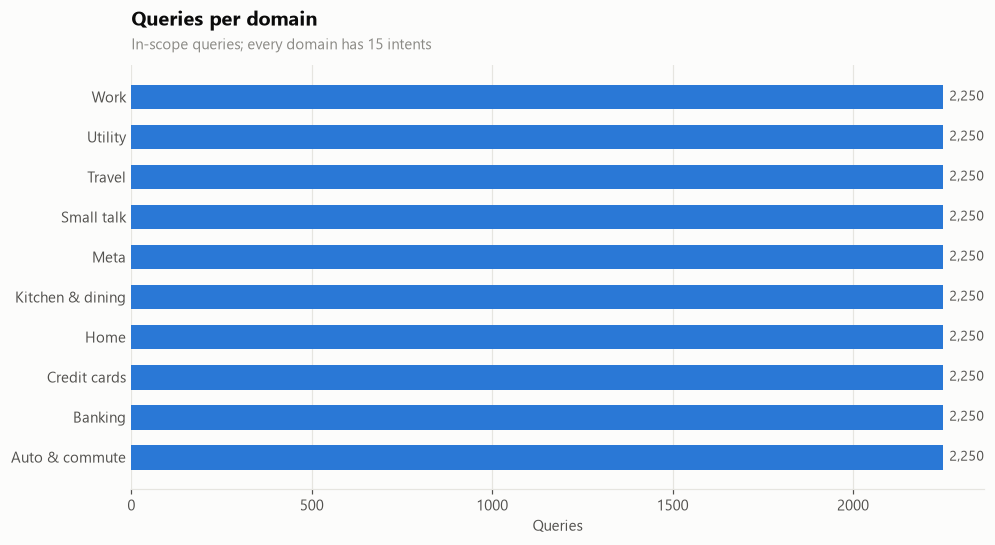

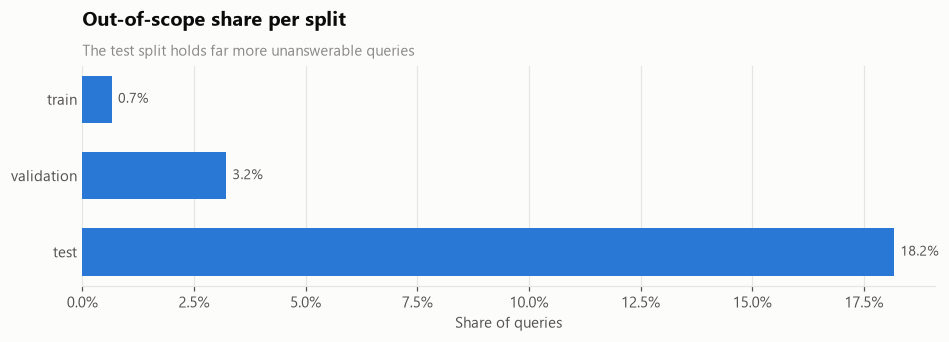

In [6]:
by_domain = clinc[~clinc["out_of_scope"]].groupby("domain").size().sort_values()
hbar(by_domain, "Queries per domain", "In-scope queries; every domain has 15 intents", xlabel="Queries")
plt.show()

oos_share = clinc.groupby("split")["out_of_scope"].mean().reindex(["train", "validation", "test"]) * 100
hbar(oos_share[::-1], "Out-of-scope share per split", "The test split holds far more unanswerable queries",
     fmt="{:.1f}%", xlabel="Share of queries")
plt.gca().xaxis.set_major_formatter(PercentFormatter())
plt.show()

In-scope classes are **perfectly balanced**: every intent has 150 queries (100 train, 20 validation, 30 test),
so no class weighting or resampling is needed. Out-of-scope queries are rare in training but make up
18% of the test split, which deliberately tests whether an assistant can tell when it should *not* act.

## 5. CLINC150: query length

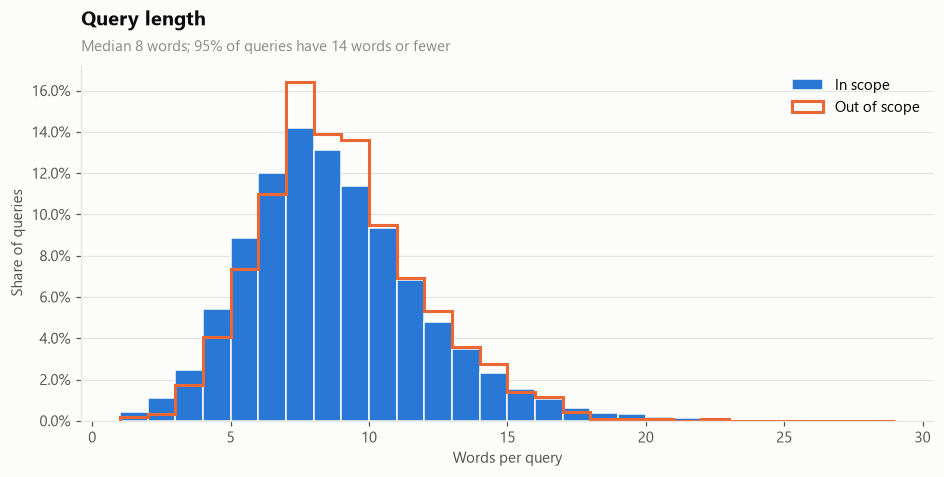

,Mean words,Median words,Longest
domain,,,
Meta,5.700000,6.000000,19.000000
Small talk,6.300000,6.000000,21.000000
Utility,6.700000,6.000000,18.000000
Home,8.300000,8.000000,22.000000
Out of scope,8.500000,8.000000,22.000000
Work,8.600000,8.000000,22.000000
Kitchen & dining,8.900000,8.000000,24.000000
Banking,9.300000,9.000000,22.000000
Auto & commute,9.400000,9.000000,25.000000


In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
bins = range(1, clinc["words"].max() + 2)
ax.hist(clinc.loc[~clinc["out_of_scope"], "words"], bins=bins, color=BLUE, density=True, label="In scope",
        edgecolor=SURFACE, linewidth=1)
ax.hist(clinc.loc[clinc["out_of_scope"], "words"], bins=bins, histtype="step", color=ORANGE, lw=2, density=True,
        label="Out of scope")
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.grid(axis="x", visible=False)
ax.set(xlabel="Words per query", ylabel="Share of queries"); ax.legend()
titled(ax, "Query length", f"Median {clinc['words'].median():.0f} words; 95% of queries have "
       f"{clinc['words'].quantile(0.95):.0f} words or fewer")
plt.show()

table(clinc.groupby("domain")["words"].describe()[["mean", "50%", "max"]]
      .rename(columns={"mean": "Mean words", "50%": "Median words", "max": "Longest"}).sort_values("Mean words").round(1))

Assistant requests are **short**: the middle half of queries have 6–10 words. This matches Aura's design, where
the orchestrator plans from one short request rather than a long document.

## 6. CLINC150: vocabulary

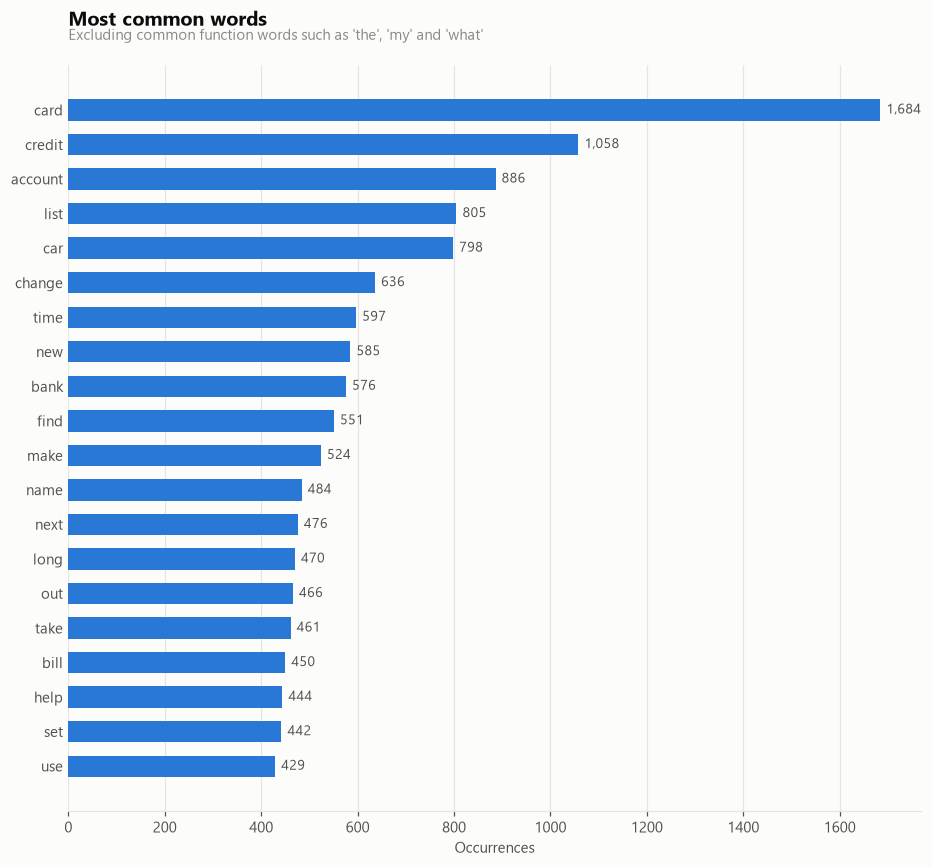

In [8]:
STOP = set('''a an the i me my you your it its is are was be am to of in on for at by with and or but if do does
did can could would should will what how when where who which that this there please tell know want need
much many any some get have has from up about so just than then not no yes as like what's i'm it's i'd don't can't'''.split())

tokens = clinc["text"].str.lower().str.findall(r"[a-z']+").explode()
content = tokens[~tokens.isin(STOP) & (tokens.str.len() > 2)]
top = content.value_counts().head(20).sort_values()

kpis([("Words in total", f"{len(tokens):,}"), ("Distinct words", f"{tokens.nunique():,}"),
      ("Words used only once", f"{(tokens.value_counts() == 1).sum():,}")])
hbar(top, "Most common words", "Excluding common function words such as 'the', 'my' and 'what'", xlabel="Occurrences")
plt.show()

In [9]:
words = clinc.assign(word=clinc["text"].str.lower().str.findall(r"[a-z']+")).explode("word")
words = words[~words["word"].isin(STOP) & (words["word"].str.len() > 2)]
top_by_domain = (words.groupby("domain")["word"].agg(lambda w: ", ".join(w.value_counts().head(6).index))
                 .to_frame("Most frequent words"))
table(top_by_domain)

,Most frequent words
domain,
Auto & commute,"car, oil, change, tires, gas, take"
Banking,"account, bill, bank, pay, number, checking"
Credit cards,"card, credit, limit, score, visa, new"
Home,"list, song, shopping, add, calendar, playlist"
Kitchen & dining,"reservation, long, make, good, reservations, calories"
Meta,"name, change, settings, phone, whisper, voice"
Out of scope,"find, best, out, list, look, phone"
Small talk,"life, name, meaning, were, pets, person"
Travel,"flight, travel, luggage, carry, visa, bank"


Each domain has its own clear vocabulary, which is why intent classification on this dataset is feasible.

## 7. CLINC150: requests Aura can handle

To connect the benchmark to the project, each CLINC150 intent was mapped **by hand** to the Aura agent that
would handle it, based on what each agent does. Intents outside Aura's features (banking, travel bookings,
car maintenance, …) are marked *Not supported*. This mapping is the author's judgement, not part of the dataset.

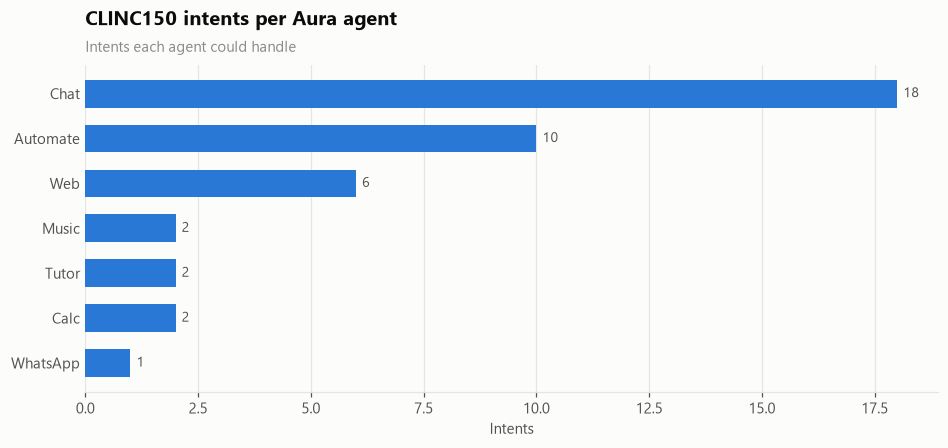

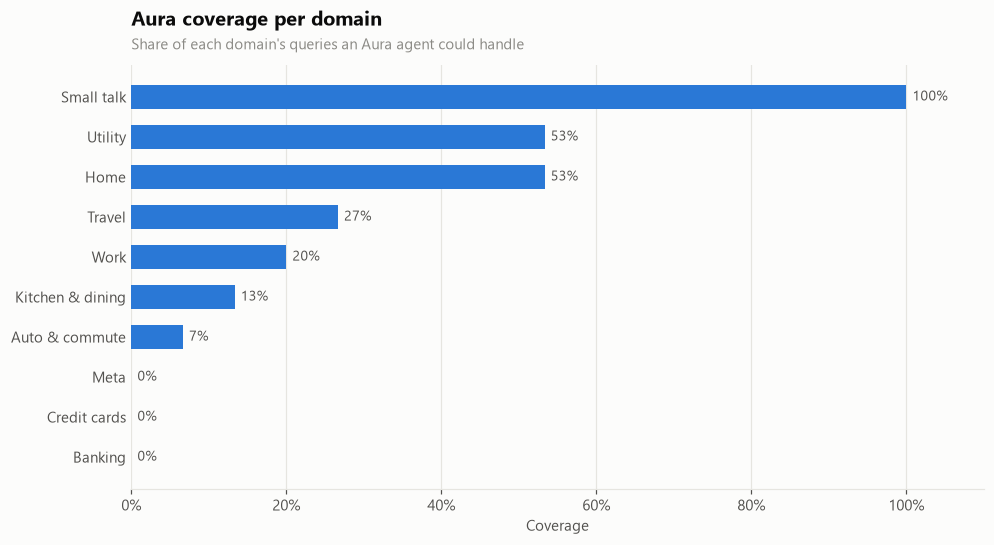

In [10]:
AURA_AGENT = {
    "Chat": ["greeting", "goodbye", "thank_you", "tell_joke", "fun_fact", "meaning_of_life", "who_made_you",
             "what_is_your_name", "are_you_a_bot", "how_old_are_you", "what_can_i_ask_you", "what_are_your_hobbies",
             "where_are_you_from", "do_you_have_pets", "who_do_you_work_for", "translate", "spelling", "definition"],
    "Automate": ["reminder", "reminder_update", "todo_list", "todo_list_update", "calendar", "calendar_update",
                 "alarm", "timer", "schedule_meeting", "meeting_schedule"],
    "Web": ["weather", "exchange_rate", "flight_status", "timezone", "traffic", "next_holiday"],
    "Music": ["play_music", "next_song"],
    "Calc": ["calculator", "measurement_conversion"],
    "Tutor": ["recipe", "ingredient_substitution"],
    "WhatsApp": ["text"],
}
agent_of = {intent: agent for agent, intents in AURA_AGENT.items() for intent in intents}
clinc["aura_agent"] = clinc["intent"].map(agent_of).fillna("Not supported")
clinc.loc[clinc["out_of_scope"], "aura_agent"] = "Out of scope"

in_scope = clinc[~clinc["out_of_scope"]]
covered = in_scope["aura_agent"] != "Not supported"
kpis([("Intents Aura covers", f"{in_scope.loc[covered, 'intent'].nunique()} of 150"),
      ("In-scope queries covered", f"{100 * covered.mean():.1f}%")])

agents = in_scope.loc[covered].groupby("aura_agent")["intent"].nunique().sort_values()
hbar(agents, "CLINC150 intents per Aura agent", "Intents each agent could handle", xlabel="Intents")
plt.show()

coverage = (100 * covered.groupby(in_scope["domain"]).mean()).sort_values()
hbar(coverage, "Aura coverage per domain", "Share of each domain's queries an Aura agent could handle",
     fmt="{:.0f}%", xlabel="Coverage")
plt.gca().xaxis.set_major_formatter(PercentFormatter()); plt.xlim(0, 110)
plt.show()

In [11]:
examples = (in_scope[covered].groupby("intent").first()[["aura_agent", "text"]]
            .rename(columns={"aura_agent": "Aura agent", "text": "Example query"})
            .sort_values("Aura agent"))
table(examples)

,Aura agent,Example query
intent,,
alarm,Automate,i'd like alarms set for 11am and 132pm
schedule_meeting,Automate,how do i set up a meeting
meeting_schedule,Automate,what if any meetings do i have today
timer,Automate,create a new timer
todo_list,Automate,repeat my to do list
reminder_update,Automate,remind me to call my mom
todo_list_update,Automate,can you cancel my todo list please
calendar_update,Automate,"you can remove the field trip from my calendar for march 12, 2019"
calendar,Automate,what is tuesday's calendar like


Aura's agents line up with the **Small talk**, **Utility** and **Home** domains, the everyday personal-assistant
requests. Domains such as banking, credit cards and car maintenance need access to outside accounts or devices,
which Aura deliberately does not have.

# Part B: Aura's own data

## 8. Data preparation

In [12]:
with open("logs/run_log.jsonl", encoding="utf-8") as f:
    log = pd.DataFrame([json.loads(line) for line in f if line.strip()])
tests = pd.read_csv("logs/test_results.csv")
tests_run1 = pd.read_csv("logs/test_results_run1.csv")

log["timestamp"] = pd.to_datetime(log["timestamp"])
log["date"] = log["timestamp"].dt.date
log["hour"] = log["timestamp"].dt.hour
log["model"] = log["model"].where(~log["model"].str.startswith("none"), "no AI (plain Python)")
log["fallback_used"] = log["fallback_used"].fillna(False).astype(bool)
log["agent"] = log["agent"].str.capitalize().replace({"Whatsapp": "WhatsApp"})

# The input / output text can hold personal messages and isn't needed for the analysis
data = log.drop(columns=["input", "output"])

table(pd.DataFrame({"Column": data.columns, "Type": data.dtypes.astype(str).values,
                    "Missing": data.isna().sum().values}).set_index("Column"))

,Type,Missing
Column,,
timestamp,datetime64[us],0
request_id,str,0
agent,str,0
model,str,0
seconds,float64,0
success,bool,0
fallback_used,bool,0
error,str,1171
date,object,0


**Cleaning steps:** timestamps parsed and split into date and hour; the three labels meaning "no AI model was called"
merged into one; missing fallback flags treated as *no fallback*; free-text `input` / `output` columns removed for privacy.
`error` is empty by design for successful calls.

## 9. Overview

In [13]:
kpis([
    ("Agent calls", f"{len(data):,}"),
    ("User requests", f"{data['request_id'].nunique():,}"),
    ("Days of use", data["date"].nunique()),
    ("Success rate", f"{100 * data['success'].mean():.1f}%"),
    ("Answered by fallback", f"{100 * data['fallback_used'].mean():.1f}%"),
    ("Median time per call", f"{data['seconds'].median():.2f} s"),
])

In [14]:
table(data["seconds"].describe().to_frame("Seconds per call").T.round(2))

,count,mean,std,min,25%,50%,75%,max
Seconds per call,1201.000000,2.690000,8.860000,0.000000,0.680000,1.170000,2.670000,277.820000


## 10. Agent usage

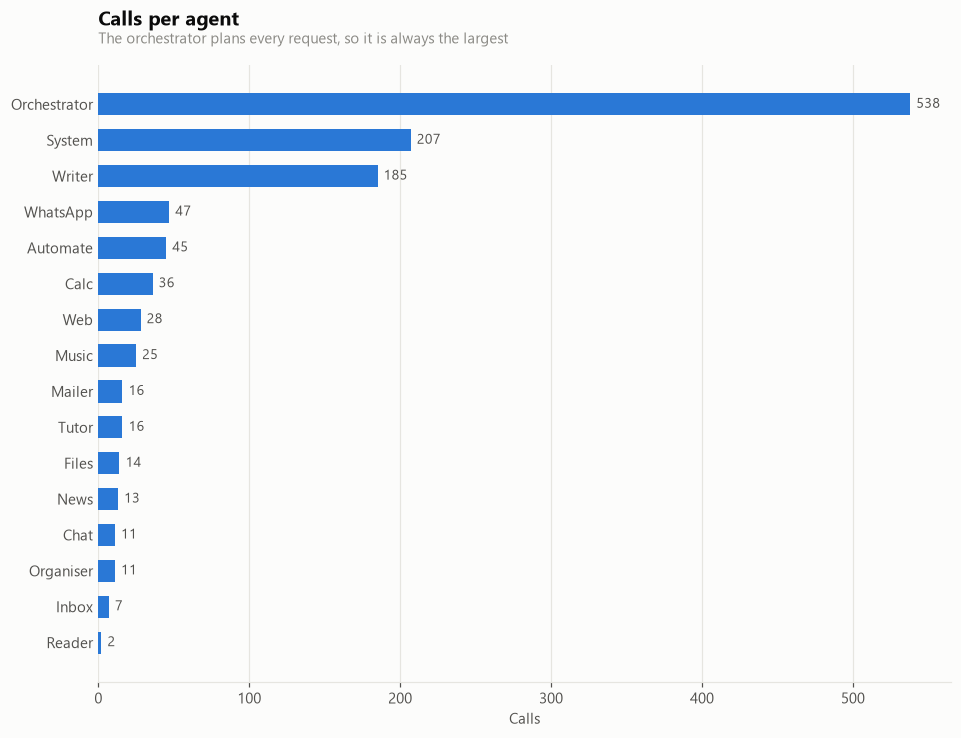

In [15]:
counts = data["agent"].value_counts().sort_values()
hbar(counts, "Calls per agent", "The orchestrator plans every request, so it is always the largest", xlabel="Calls")
plt.show()

## 11. Agent reliability

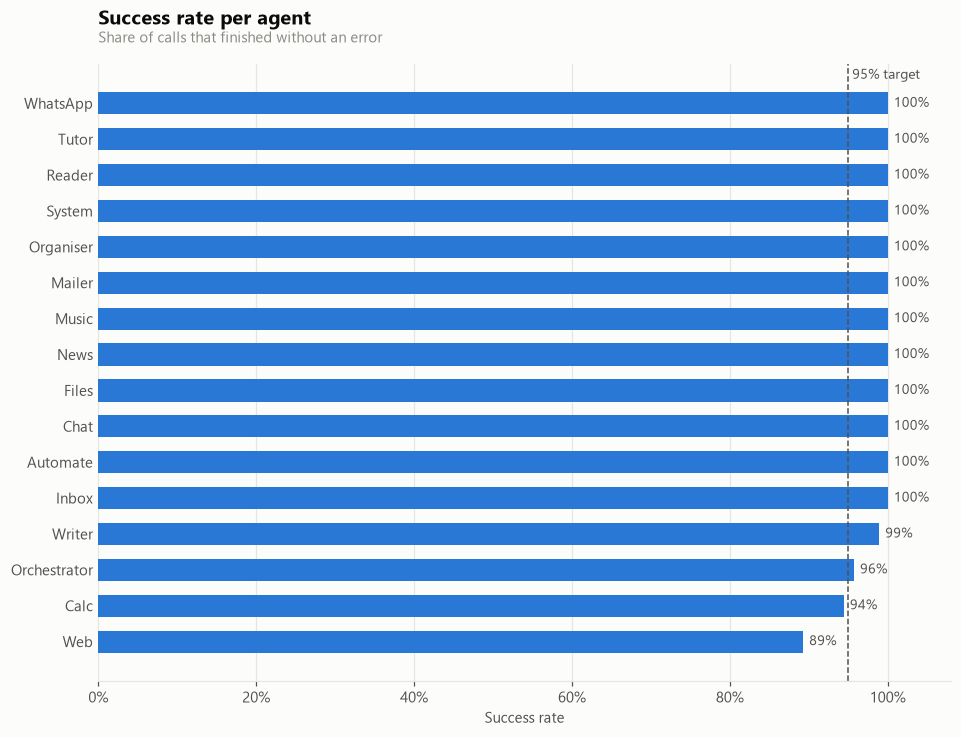

,Calls,Success rate,Median time,Fallback rate
agent,,,,
Orchestrator,538,95.7%,1.65 s,47.0%
System,207,100.0%,0.42 s,0.0%
Writer,185,98.9%,1.21 s,6.5%
WhatsApp,47,100.0%,0.01 s,0.0%
Automate,45,100.0%,0.85 s,11.1%
Calc,36,94.4%,0.00 s,0.0%
Web,28,89.3%,3.89 s,25.0%
Music,25,100.0%,2.83 s,0.0%
Mailer,16,100.0%,0.01 s,0.0%


In [16]:
by_agent = data.groupby("agent").agg(Calls=("success", "size"), Success=("success", "mean"),
                                     Median=("seconds", "median"), Fallback=("fallback_used", "mean"))
by_agent[["Success", "Fallback"]] *= 100

hbar(by_agent["Success"].sort_values(), "Success rate per agent",
     "Share of calls that finished without an error", fmt="{:.0f}%", xlabel="Success rate", ref=95)
plt.gca().xaxis.set_major_formatter(PercentFormatter()); plt.xlim(0, 108)
plt.show()

table(by_agent.sort_values("Calls", ascending=False)
      .rename(columns={"Success": "Success rate", "Median": "Median time", "Fallback": "Fallback rate"}),
      pct=("Success rate", "Fallback rate"), secs=("Median time",), ints=("Calls",))

## 12. Response time

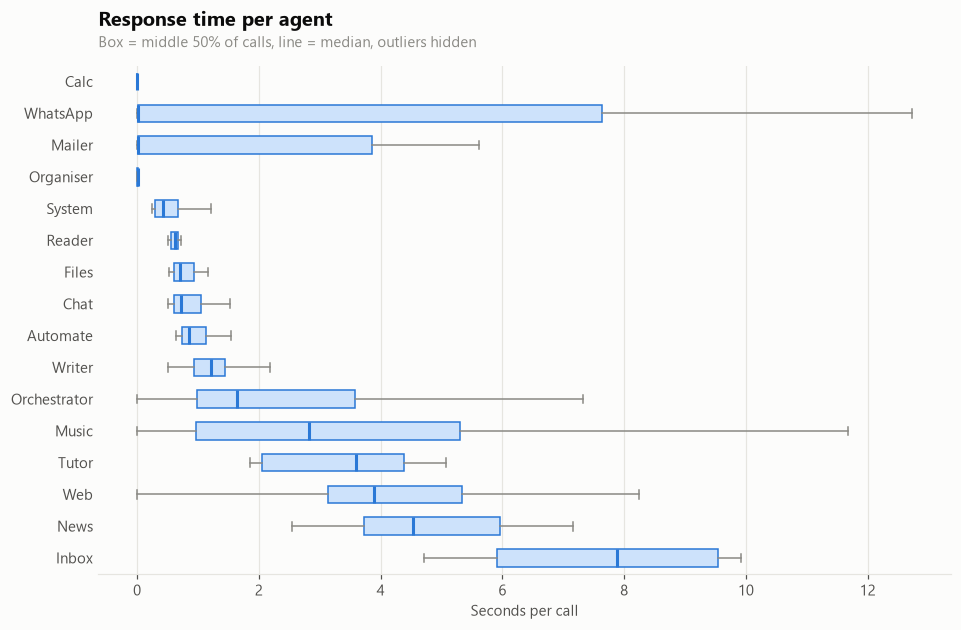

In [17]:
order = data.groupby("agent")["seconds"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot([data.loc[data["agent"] == a, "seconds"] for a in order], tick_labels=order, orientation="horizontal",
           showfliers=False, widths=0.55, patch_artist=True,
           boxprops={"facecolor": "#cde2fb", "edgecolor": BLUE}, medianprops={"color": BLUE, "lw": 2},
           whiskerprops={"color": MUTED}, capprops={"color": MUTED})
ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_xlabel("Seconds per call")
titled(ax, "Response time per agent", "Box = middle 50% of calls, line = median, outliers hidden")
plt.show()

## 13. Models

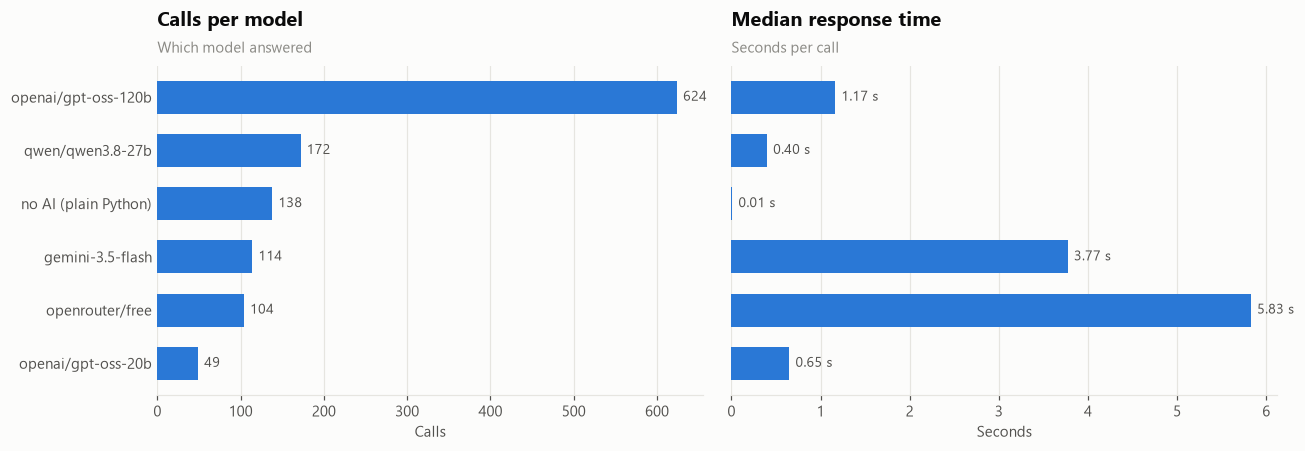

,Calls,Median time,Success rate
model,,,
openai/gpt-oss-120b,624,1.17 s,95.5%
qwen/qwen3.8-27b,172,0.40 s,100.0%
no AI (plain Python),138,0.01 s,98.6%
gemini-3.5-flash,114,3.77 s,100.0%
openrouter/free,104,5.83 s,100.0%
openai/gpt-oss-20b,49,0.65 s,100.0%


In [18]:
by_model = data.groupby("model").agg(Calls=("seconds", "size"), Median=("seconds", "median"),
                                     Success=("success", "mean")).sort_values("Calls")
by_model["Success"] *= 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
hbar(by_model["Calls"], "Calls per model", "Which model answered", xlabel="Calls", ax=a1)
hbar(by_model["Median"], "Median response time", "Seconds per call", fmt="{:.2f} s", xlabel="Seconds", ax=a2)
plt.tight_layout(); plt.show()

table(by_model.sort_values("Calls", ascending=False)
      .rename(columns={"Median": "Median time", "Success": "Success rate"}),
      pct=("Success rate",), secs=("Median time",), ints=("Calls",))

## 14. Fallback models
When the main model fails (usually a free-tier rate limit or a network error), Aura retries the same task
with a backup model, and finally with OpenRouter's free router.

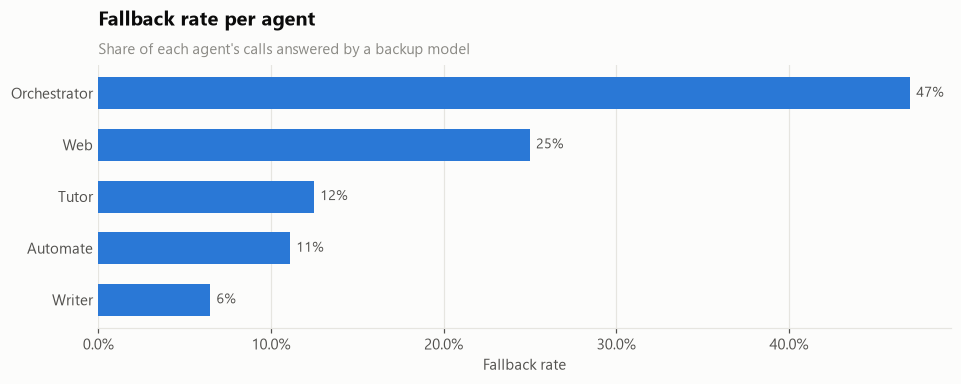

In [19]:
saved = int((data["fallback_used"] & data["success"]).sum())
kpis([("Calls rescued by a fallback model", f"{saved:,}"),
      ("Share of all calls", f"{100 * saved / len(data):.1f}%")])

rate = by_agent["Fallback"].sort_values()
hbar(rate[rate > 0], "Fallback rate per agent", "Share of each agent's calls answered by a backup model",
     fmt="{:.0f}%", xlabel="Fallback rate")
plt.gca().xaxis.set_major_formatter(PercentFormatter())
plt.show()

## 15. Error analysis

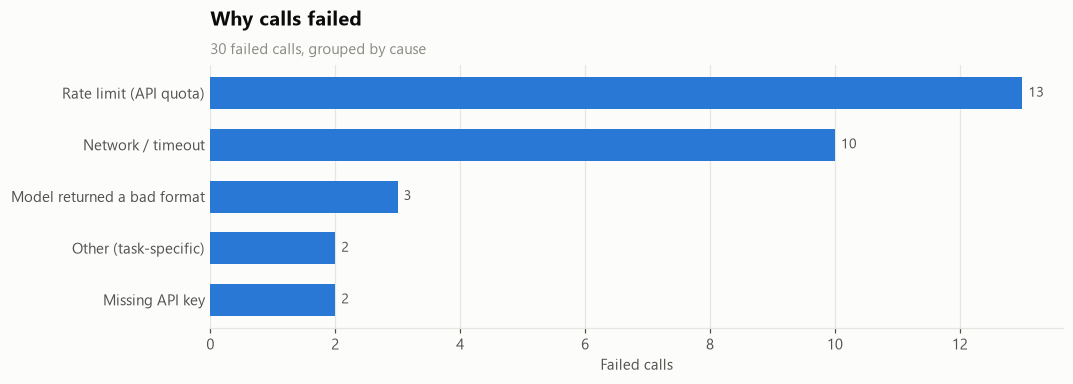

In [20]:
errors = data.loc[~data["success"], "error"].fillna("unknown")

def error_type(e):
    e = e.lower()
    if "429" in e or "rate limit" in e: return "Rate limit (API quota)"
    if "network" in e or "connection" in e or "timeout" in e: return "Network / timeout"
    if "json" in e: return "Model returned a bad format"
    if "key" in e: return "Missing API key"
    return "Other (task-specific)"

types = errors.map(error_type).value_counts()
hbar(types.sort_values(), "Why calls failed", f"{len(errors)} failed calls, grouped by cause", xlabel="Failed calls")
plt.show()

## 16. Usage over time

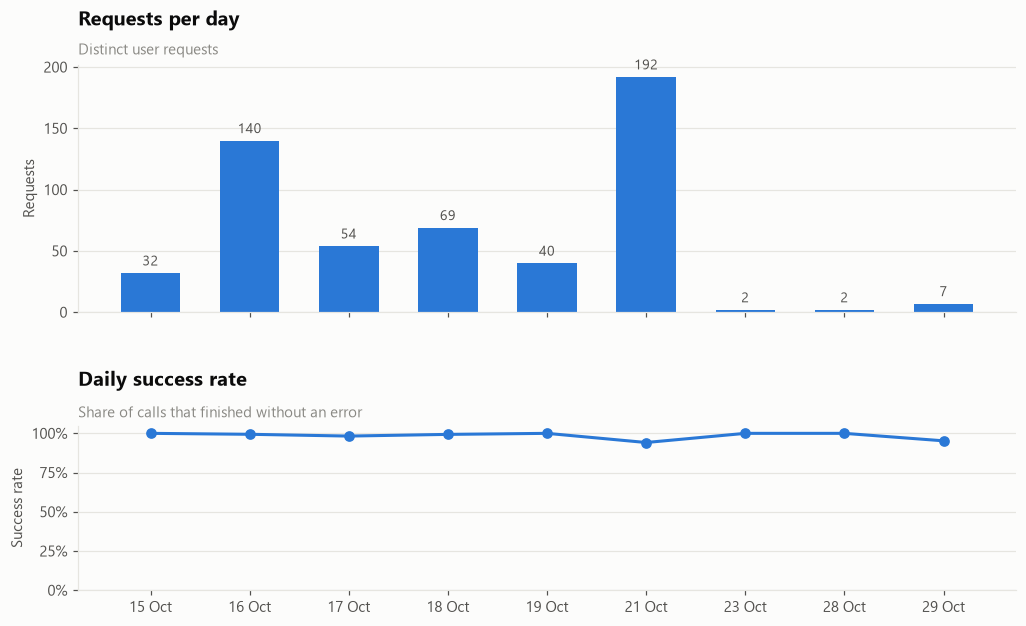

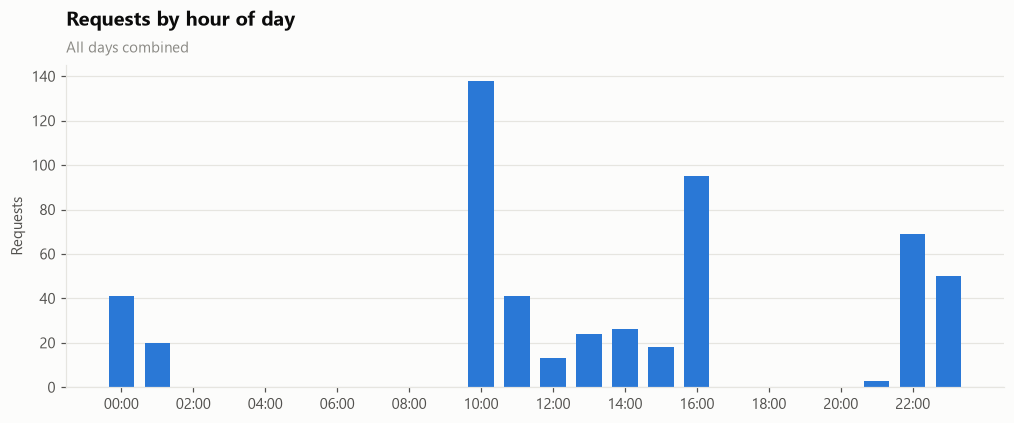

In [21]:
daily = data.groupby("date").agg(requests=("request_id", "nunique"), success=("success", "mean"))
x = [d.strftime("%d %b") for d in daily.index]

# Two panels on one time axis instead of one chart with two y-scales
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, gridspec_kw={"height_ratios": [3, 2], "hspace": 0.55})
bars = a1.bar(x, daily["requests"], color=BLUE, width=0.6)
a1.bar_label(bars, padding=3, color=INK_2, fontsize=9); a1.grid(axis="x", visible=False)
a1.set_ylabel("Requests"); titled(a1, "Requests per day", "Distinct user requests")

a2.plot(x, 100 * daily["success"], color=BLUE, lw=2, marker="o", ms=6)
a2.set_ylim(0, 105); a2.yaxis.set_major_formatter(PercentFormatter()); a2.grid(axis="x", visible=False)
a2.set_ylabel("Success rate"); titled(a2, "Daily success rate", "Share of calls that finished without an error")
plt.show()

hourly = data.groupby("hour")["request_id"].nunique().reindex(range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(hourly.index, hourly.values, color=BLUE, width=0.7)
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 2)])
ax.grid(axis="x", visible=False); ax.set_ylabel("Requests")
titled(ax, "Requests by hour of day", "All days combined")
plt.show()

## 17. Multi-step requests

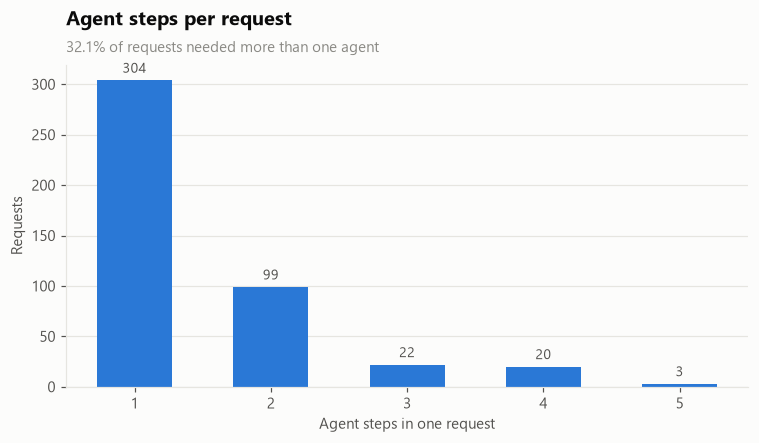

In [22]:
steps = data[data["agent"] != "Orchestrator"].groupby("request_id").size()
dist = steps.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(dist.index.astype(str), dist.values, color=BLUE, width=0.55)
ax.bar_label(bars, padding=3, color=INK_2, fontsize=9); ax.grid(axis="x", visible=False)
ax.set(xlabel="Agent steps in one request", ylabel="Requests")
titled(ax, "Agent steps per request", f"{100 * (steps > 1).mean():.1f}% of requests needed more than one agent")
plt.show()

## 18. Evaluation: routing accuracy
Each test request is **labelled** with the agents that should handle it, in order. A test passes when Aura chooses
exactly those agents and no step fails, so the pass rate is the orchestrator's **classification accuracy**.

In [23]:
def accuracy(df): return 100 * (df["Result"] == "PASS").mean()
shared = tests_run1.merge(tests, on="Request", suffixes=("_run1", "_latest"))
shared_before = 100 * (shared["Result_run1"] == "PASS").mean()
shared_after = 100 * (shared["Result_latest"] == "PASS").mean()

kpis([("Accuracy, latest run", f"{accuracy(tests):.1f}%"),
      ("Tests in latest run", len(tests)),
      ("Accuracy, earlier run", f"{accuracy(tests_run1):.1f}%"),
      (f"Same {len(shared)} tests: before → after", f"{shared_before:.0f}% → {shared_after:.0f}%")])

The latest run added harder requests (tasks, automations), so its overall score is not directly comparable with the
earlier, smaller run. On the requests both runs share, accuracy is unchanged.

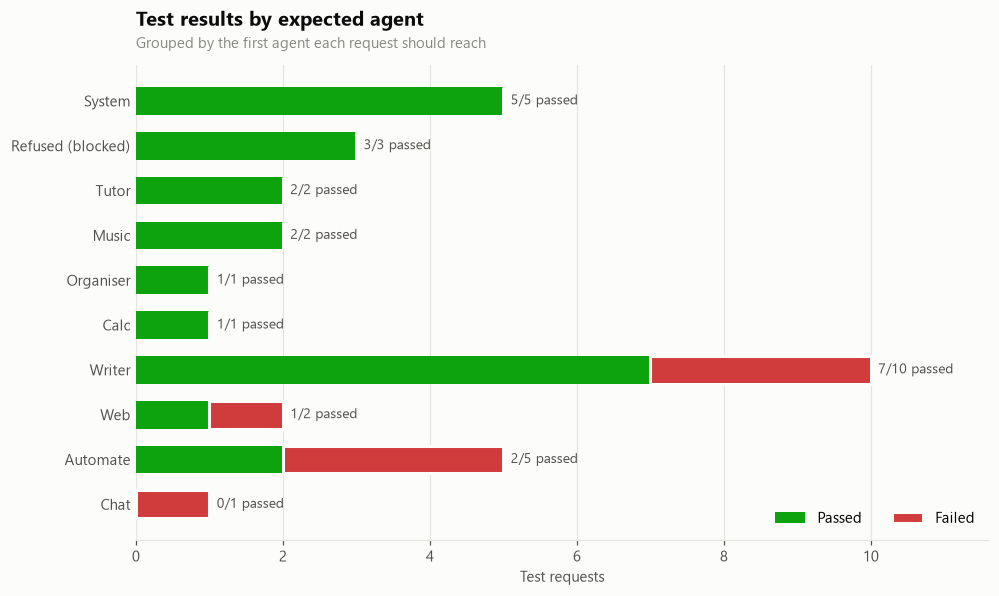

,Expected,Got
Request,,
who won the cricket world cup,web,web [FAILED]
write hello to mahi and send it on whatsapp,"writer, whatsapp",(nothing) [FAILED]
write a complaint letter to the hostel warden,"writer, system",(nothing) [FAILED]
tell me a joke,chat,(nothing) [FAILED]
"write a resignation letter, open it, and then","writer, system, system",(nothing) [FAILED]
every day at 8 am give me today's tech news,automate,(nothing) [FAILED]
add buy milk to my tasks,automate,(nothing) [FAILED]
"save open vs code, spotify and gmail as study",automate,(nothing) [FAILED]


In [24]:
tests["First agent"] = tests["Expected"].str.split(",").str[0].str.strip().str.capitalize().replace({"Refuse": "Refused (blocked)", "Whatsapp": "WhatsApp"})
per = tests.groupby("First agent")["Result"].agg(Tests="size", Passed=lambda r: (r == "PASS").sum())
per["Accuracy"] = 100 * per["Passed"] / per["Tests"]
per = per.sort_values(["Accuracy", "Tests"])

fig, ax = plt.subplots(figsize=(10, 0.42 * len(per) + 1.4))
ax.barh(per.index, per["Passed"], color=GOOD, height=0.62, label="Passed")
ax.barh(per.index, per["Tests"] - per["Passed"], left=per["Passed"], color=CRITICAL, height=0.62,
        edgecolor=SURFACE, linewidth=2, label="Failed")
for i, (t, p) in enumerate(zip(per["Tests"], per["Passed"])):
    ax.text(t + 0.1, i, f"{p}/{t} passed", va="center", color=INK_2, fontsize=9)
ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_xlabel("Test requests"); ax.set_xlim(0, per["Tests"].max() + 1.6)
ax.legend(loc="lower right", ncol=2)
titled(ax, "Test results by expected agent", "Grouped by the first agent each request should reach")
plt.show()

table(tests.loc[tests["Result"] != "PASS", ["Request", "Expected", "Got"]].set_index("Request"))

## 19. Findings and conclusions

In [25]:
best = by_agent[by_agent["Calls"] >= 10]
findings = pd.DataFrame([
    ("CLINC150 size", f"{len(clinc):,} labelled queries, 150 intents in 10 domains, perfectly balanced"),
    ("CLINC150 quality", f"{(per_text['labels'] > 1).sum()} repeated queries with conflicting labels; no empty rows"),
    ("Typical request", f"{clinc['words'].median():.0f} words (median)"),
    ("Aura coverage", f"{in_scope.loc[covered, 'intent'].nunique()} of 150 intents ({100 * covered.mean():.1f}% of queries)"),
    ("Scale", f"{len(data):,} agent calls from {data['request_id'].nunique()} requests over {data['date'].nunique()} days"),
    ("Reliability", f"{100 * data['success'].mean():.1f}% of calls succeeded"),
    ("Most used agent", f"{counts.drop('Orchestrator').idxmax()} (after the Orchestrator)"),
    ("Most / least reliable", f"{best['Success'].idxmax()} / {best['Success'].idxmin()} (agents with 10+ calls)"),
    ("Fallback value", f"{saved} calls ({100 * saved / len(data):.1f}%) succeeded only because of a backup model"),
    ("Main failure cause", f"{types.idxmax()}: {types.max()} of {len(errors)} failures"),
    ("Routing accuracy", f"{accuracy(tests):.1f}% on {len(tests)} labelled tests"),
], columns=["Finding", "Result"]).set_index("Finding")
table(findings)

,Result
Finding,
CLINC150 size,"23,700 labelled queries, 150 intents in 10 domains, perfectly balanced"
CLINC150 quality,4 repeated queries with conflicting labels; no empty rows
Typical request,8 words (median)
Aura coverage,41 of 150 intents (27.3% of queries)
Scale,"1,201 agent calls from 538 requests over 9 days"
Reliability,97.5% of calls succeeded
Most used agent,System (after the Orchestrator)
Most / least reliable,Automate / Web (agents with 10+ calls)
Fallback value,279 calls (23.2%) succeeded only because of a backup model


**Conclusions**
- CLINC150 shows that real assistant requests are short, single-sentence and spread evenly over many topics. Aura's
  agents cover the everyday personal-assistant part of that space (small talk, reminders, music, maths, weather),
  not services that need outside accounts such as banking or travel bookings.
- Aura is reliable for everyday tasks. Most failures come from **free API rate limits and network errors**, not from
  wrong answers, which is why the fallback chain (main model → backup model → OpenRouter free) matters.
- Agents that mostly run plain Python (Calc, Organiser, Mailer, WhatsApp) answer in under 0.1 s; agents that call
  an AI model and the internet (Web, News, Inbox) are the slowest.
- Measured like a classifier on a labelled test set, the orchestrator routes three in four requests correctly; the
  failed tests show which kinds of request need better prompts or rules.

**Limitations:** the CLINC150-to-Aura mapping is the author's judgement and Aura was not run on CLINC150, so
coverage is what Aura's agents are designed for, not measured accuracy. Aura's own data comes from one user over about two weeks and the test set is small (32 requests), so these
results describe this project rather than all users.